<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/susy_qm/susyqm_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Supersymmetric Quantum Mechanics* — `susyqm_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SUSYQM Ch 2 Figures — Colab Notebook
**Supersymmetric Quantum Mechanics · Chapter 2: Supersymmetry and the Path Integral**

| Figure | Section | Content |
|--------|---------|---------|
| fig01  | §2.1   | Path integral: bosonic vs fermionic boundary conditions (periodic/anti-periodic) |
| fig02  | §2.1.1 | Harmonic oscillator partition function and Witten index via path integral |
| fig03  | §2.2   | Instanton profile: kink solution x(τ) interpolating between minima |
| fig04  | §2.2.2 | Dilute gas approximation — multi-instanton configurations |
| fig05  | §2.3   | Instanton + SUSY: Fermi zero mode and ground state energy lifting |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
from scipy.special import erf
import os

BG    = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
PURP  = '#c792ea'; BLUE = '#7ec8e3'; YELL = '#f9c74f'
GREEN = '#90ee90'; RED  = '#e07070'; ORAN = '#e8a838'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': PURP, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete — SUSYQM Ch 2 figures.')


Setup complete — SUSYQM Ch 2 figures.


  saved -> figures/ch02/fig01_boundary_conditions.png


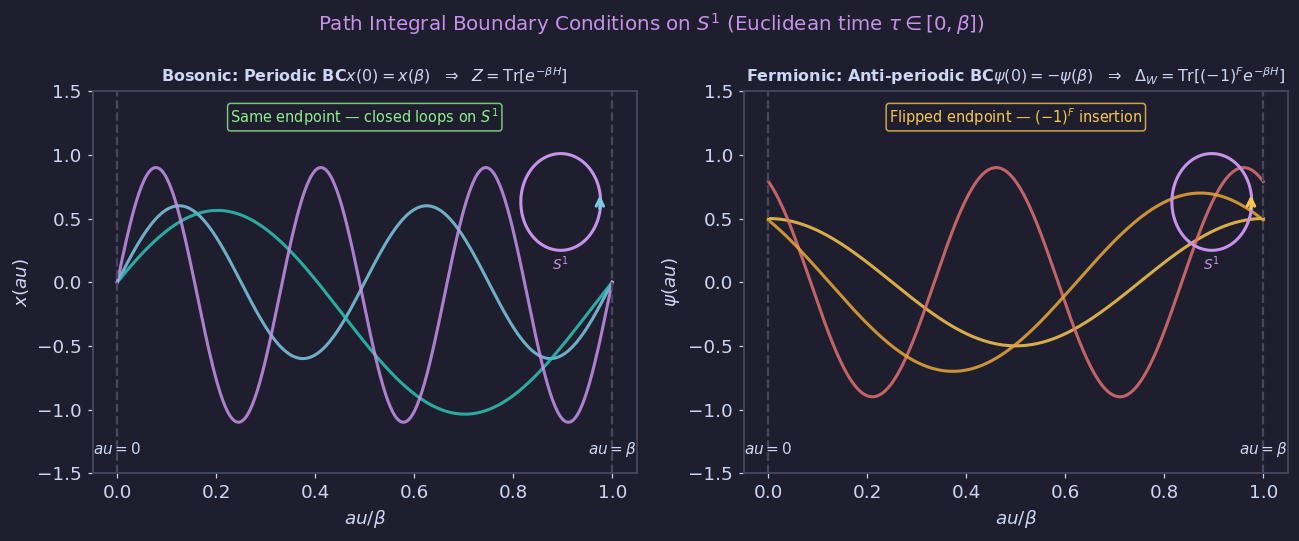

In [2]:
# ── Figure 1: Bosonic (periodic) vs Fermionic (anti-periodic) BCs ───────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Path Integral Boundary Conditions on $S^1$ (Euclidean time $\\tau \\in [0,\\beta]$)',
             color=PURP, fontsize=13)

tau = np.linspace(0, 1, 400)  # normalised [0,β]

# Left: bosonic — periodic BCs, partition function Z = Tr[e^{-βH}]
ax = axes[0]
ax.set_facecolor(BG)
ax.set_title('Bosonic: Periodic BC' + r'$x(0)=x(\beta)$  $\Rightarrow$  $Z=\mathrm{Tr}[e^{-\beta H}]$',
             color=FG, fontsize=10.5)

for k, (amp, freq, phase, col) in enumerate([
    (0.6, 2, 0,    BLUE),
    (0.8, 1, 0.3,  TEAL),
    (1.0, 3, 0.1,  PURP),
]):
    y = amp * np.sin(2*np.pi*freq*tau + phase)
    y -= y[0]  # enforce x(0)=0 without loss of generality
    ax.plot(tau, y, color=col, lw=2, alpha=0.85)

ax.axvline(0, color=EDGE, lw=1.5, ls='--')
ax.axvline(1, color=EDGE, lw=1.5, ls='--')
ax.text(0, -1.35, r'$\tau=0$', ha='center', fontsize=10, color=FG)
ax.text(1, -1.35, r'$\tau=\beta$', ha='center', fontsize=10, color=FG)
ax.set_xlabel(r'$\tau/\beta$'); ax.set_ylabel(r'$x(\tau)$')
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-1.5, 1.5)
ax.text(0.5, 1.25, 'Same endpoint — closed loops on $S^1$',
        ha='center', fontsize=9.5, color=GREEN,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=GREEN, alpha=0.8))

# Right: fermionic — anti-periodic BCs, Witten index
ax = axes[1]
ax.set_facecolor(BG)
ax.set_title('Fermions: anti-periodic ' +
             r'$\psi(\beta)=-\psi(0)$ $\Rightarrow$ $Z$;  periodic $\Rightarrow$ $\Delta_W=\mathrm{Tr}[(-1)^F e^{-\beta H}]$',
             color=FG, fontsize=10.5)

for amp, freq, phase, col in [(0.5, 0.5, 0, YELL), (0.9, 1.5, 0.5, RED), (0.7, 0.5, 0.8, ORAN)]:
    y = amp * np.cos(np.pi*(2*freq+1)*tau + phase)
    ax.plot(tau, y, color=col, lw=2, alpha=0.85)

ax.axvline(0, color=EDGE, lw=1.5, ls='--')
ax.axvline(1, color=EDGE, lw=1.5, ls='--')
ax.text(0, -1.35, r'$\tau=0$', ha='center', fontsize=10, color=FG)
ax.text(1, -1.35, r'$\tau=\beta$', ha='center', fontsize=10, color=FG)
ax.set_xlabel(r'$\tau/\beta$'); ax.set_ylabel(r'$\psi(\tau)$')
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-1.5, 1.5)
ax.text(0.5, 1.25, r'Sign flip from Grassmann trace; $(-1)^F$ undoes it',
        ha='center', fontsize=9.5, color=YELL,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=YELL, alpha=0.8))

# Shared circle schematic (small inset)
for i, ax in enumerate(axes):
    ins = ax.inset_axes([0.75, 0.52, 0.22, 0.38])
    ins.set_facecolor(BG)
    th = np.linspace(0, 2*np.pi, 200)
    ins.plot(np.cos(th), np.sin(th), color=PURP, lw=2)
    arrow_col = BLUE if i==0 else YELL
    ins.annotate('', xy=(np.cos(0.2), np.sin(0.2)),
                 xytext=(np.cos(-0.2), np.sin(-0.2)),
                 arrowprops=dict(arrowstyle='->', color=arrow_col, lw=2))
    ins.set_xlim(-1.5,1.5); ins.set_ylim(-1.5,1.5)
    ins.axis('off')
    ins.text(0, -1.4, r'$S^1$', ha='center', fontsize=9, color=PURP)

plt.tight_layout()
save('fig01_boundary_conditions.png', fig)


  saved -> figures/ch02/fig02_harmonic_oscillator.png


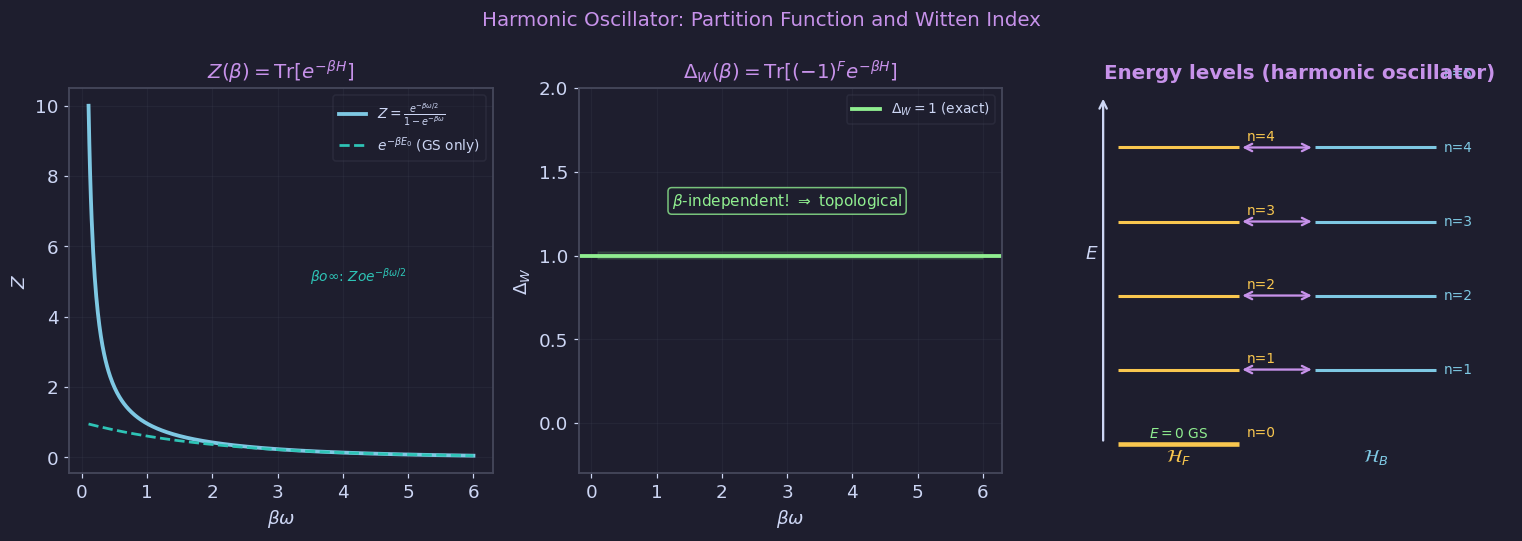

In [3]:
# ── Figure 2: Harmonic oscillator — Z and Witten index vs β ─────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Harmonic Oscillator: Partition Function and Witten Index',
             color=PURP, fontsize=13)

omega = 1.0
beta  = np.linspace(0.1, 6, 500)

# Exact Z = Tr[e^{-βH}] = sum_{n=0}^inf e^{-β(n+1/2)ω}
Z_exact = (1 + np.exp(-beta*omega)) / (1 - np.exp(-beta*omega))   # SUSY oscillator: coth(beta*omega/2)
# Witten index Δ_W = Tr[(-1)^F e^{-βH}] = 1 (constant, independent of β)
W_exact = np.ones_like(beta)

# Path integral evaluation
# Z ≈ e^{-βω/2}/(1-e^{-βω}) — matches
# Δ_W = 1 for quadratic h (unique bosonic GS)

ax = axes[0]
ax.set_facecolor(BG)
ax.set_title(r'$Z(\beta)=\mathrm{Tr}[e^{-\beta H}]$', color=PURP)
ax.plot(beta, Z_exact, color=BLUE, lw=2.5, label=r'$Z = \coth(\beta\omega/2)$ (SUSY)')
ax.plot(beta, np.ones_like(beta), color=TEAL, lw=1.8, ls='--',
        label=r'$e^{-\beta E_0}=1$ (GS only, $E_0=0$)')
ax.set_xlabel(r'$\beta\omega$'); ax.set_ylabel(r'$Z$')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2)
ax.text(3.5, Z_exact[0]*0.5, r'$\beta\to\infty$: $Z\to1$ (one $E=0$ state)',
        fontsize=9, color=TEAL)

ax = axes[1]
ax.set_facecolor(BG)
ax.set_title(r'$\Delta_W(\beta)=\mathrm{Tr}[(-1)^F e^{-\beta H}]$', color=PURP)
ax.axhline(1, color=GREEN, lw=2.5, ls='-', label=r'$\Delta_W=1$ (exact)')
ax.fill_between(beta, 0.98, 1.02, color=GREEN, alpha=0.12)
ax.set_xlabel(r'$\beta\omega$'); ax.set_ylabel(r'$\Delta_W$')
ax.set_ylim(-0.3, 2.0); ax.grid(True, alpha=0.2)
ax.legend(fontsize=9)
ax.text(3, 1.3,
        r'$\beta$-independent!' + ' ' + r'$\Rightarrow$ topological',
        ha='center', fontsize=10, color=GREEN,
        bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=GREEN, alpha=0.8))

ax = axes[2]
ax.set_facecolor(BG)
ax.set_title('Energy levels (harmonic oscillator)', color=PURP)
ns = np.arange(5)
E_F = omega * ns                    # HF: n=0,1,2,...
E_B = omega * (ns + 1)              # HB: n=1,2,...
for n, E in enumerate(E_F):
    ax.hlines(E, 0.2, 1.0, colors=YELL, lw=3 if n==0 else 2)
    ax.text(1.05, E+0.15, f'n={n}', color=YELL, fontsize=9, va='center')
for n, E in enumerate(E_B):
    ax.hlines(E, 1.5, 2.3, colors=BLUE, lw=2)
    ax.text(2.35, E, f'n={n+1}', color=BLUE, fontsize=9, va='center')
    ax.annotate('', xy=(1.5, E), xytext=(1.0, E),
                arrowprops=dict(arrowstyle='<->', color=PURP, lw=1.5))
ax.text(0.6, -0.25, r'$\mathcal{H}_B$', ha='center', fontsize=12,
        color=YELL, fontweight='bold')
ax.text(1.9, -0.25, r'$\mathcal{H}_F$', ha='center', fontsize=12,
        color=BLUE, fontweight='bold')
ax.text(0.6, 0.08, r'$E=0$ GS', ha='center', fontsize=9, color=GREEN)
ax.set_xlim(0, 2.8); ax.set_ylim(-0.4, 4.8)
ax.axis('off')
ax.annotate('', xy=(0.1, 4.7), xytext=(0.1, 0),
            arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))
ax.text(0.07, 2.5, r'$E$', ha='right', fontsize=12, color=FG)

plt.tight_layout()
save('fig02_harmonic_oscillator.png', fig)


  saved -> figures/ch02/fig03_instanton.png


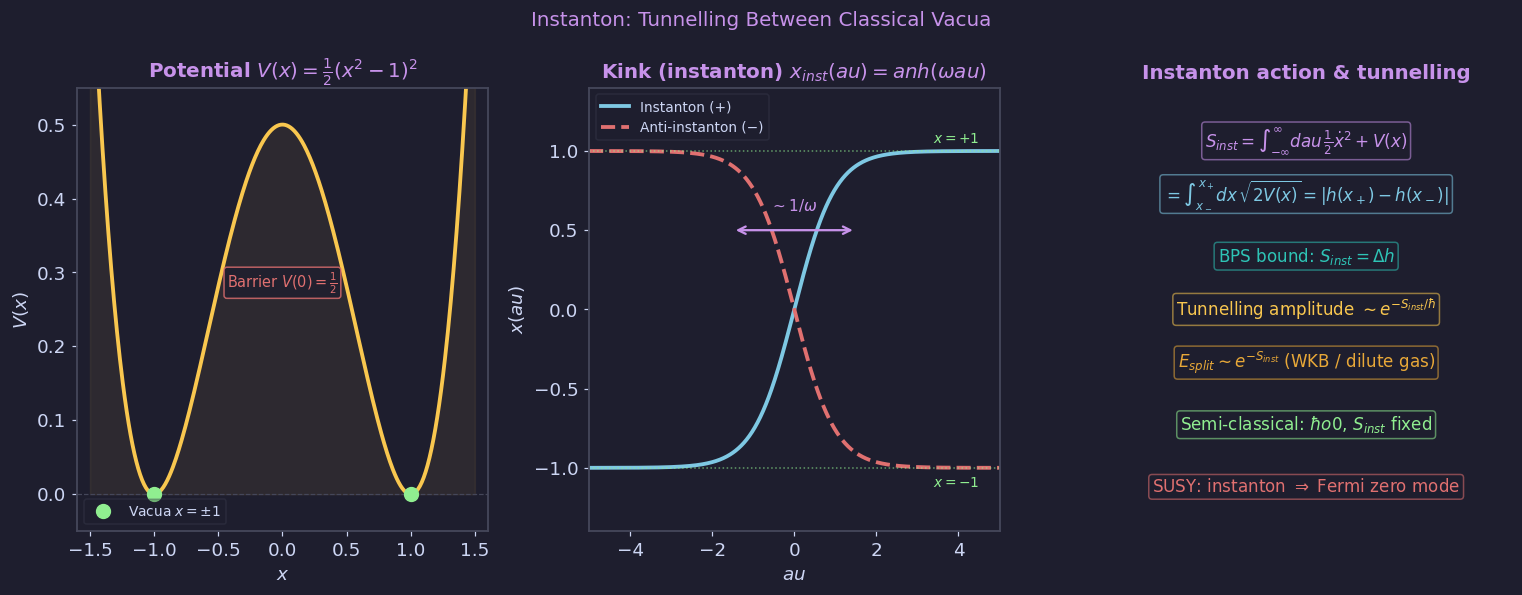

In [4]:
# ── Figure 3: Instanton (kink) solution x(τ) ───────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
fig.suptitle('Instanton: Tunnelling Between Classical Vacua',
             color=PURP, fontsize=13)

tau = np.linspace(-5, 5, 600)

# Double well: h(x) = λ(x^3/3 - x), V(x) = (h')^2/2 = (λ(x^2-1))^2/2
# Classical vacua at x = ±1
# Instanton (BPS) solution: x_inst(τ) = tanh(ω(τ-τ_0))  with ω = 1

omega = 1.0
tau0  = 0.0

x_inst    = np.tanh(omega * (tau - tau0))
x_antinst = -np.tanh(omega * (tau - tau0))

V_x   = np.linspace(-1.5, 1.5, 400)
V_val = 0.5 * (V_x**2 - 1)**2

# Left: V(x) showing the two minima
ax = axes[0]
ax.set_facecolor(BG)
ax.set_title(r'Potential $V(x) = \frac{1}{2}(x^2-1)^2$', color=PURP)
ax.plot(V_x, V_val, color=YELL, lw=2.5)
ax.fill_between(V_x, 0, V_val, color=YELL, alpha=0.07)
ax.axhline(0, color=EDGE, lw=0.8, ls='--')
ax.plot([-1, 1], [0, 0], 'o', color=GREEN, ms=9, zorder=5, label=r'Vacua $x=\pm1$')
ax.set_xlabel(r'$x$'); ax.set_ylabel(r'$V(x)$')
ax.set_xlim(-1.6, 1.6); ax.set_ylim(-0.05, 0.55)
ax.legend(fontsize=9)
ax.text(0, 0.28, r'Barrier $V(0)=\frac{1}{2}$', ha='center', fontsize=9.5, color=RED,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=RED, alpha=0.8))

# Middle: instanton and anti-instanton in τ
ax = axes[1]
ax.set_facecolor(BG)
ax.set_title(r'Kink (instanton) $x_{inst}(\tau)=\tanh(\omega\tau)$', color=PURP)
ax.plot(tau, x_inst,    color=BLUE, lw=2.5, label='Instanton (+)')
ax.plot(tau, x_antinst, color=RED,  lw=2.5, ls='--', label='Anti-instanton (−)')
ax.axhline( 1, color=GREEN, lw=1, ls=':', alpha=0.6)
ax.axhline(-1, color=GREEN, lw=1, ls=':', alpha=0.6)
ax.text(4.5,  1.05, r'$x=+1$', ha='right', fontsize=9, color=GREEN)
ax.text(4.5, -1.12, r'$x=-1$', ha='right', fontsize=9, color=GREEN)
ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$x(\tau)$')
ax.set_xlim(-5, 5); ax.set_ylim(-1.4, 1.4)
ax.legend(fontsize=9)

# Mark the size of instanton
ax.annotate('', xy=(1.5, 0.5), xytext=(-1.5, 0.5),
            arrowprops=dict(arrowstyle='<->', color=PURP, lw=1.5))
ax.text(0, 0.62, r'$\sim 1/\omega$', ha='center', fontsize=10, color=PURP)

# Right: action and tunnelling amplitude
ax = axes[2]
ax.set_facecolor(BG)
ax.set_title('Instanton action & tunnelling', color=PURP)
ax.axis('off')

content = [
    (0.5, 0.88, r'$S_{inst} = \int_{-\infty}^\infty d\tau\, \frac{1}{2}\dot{x}^2 + V(x)$',
     PURP),
    (0.5, 0.76, r'$= \int_{x_-}^{x_+} dx\,\sqrt{2V(x)} = |h(x_+)-h(x_-)|$',
     BLUE),
    (0.5, 0.62, r'BPS bound: $S_{inst} = \Delta h$', TEAL),
    (0.5, 0.50, r'Tunnelling amplitude $\sim e^{-S_{inst}/\hbar}$', YELL),
    (0.5, 0.38, r'$E_{split} \sim e^{-S_{inst}}$ (WKB / dilute gas)', ORAN),
    (0.5, 0.24, r'Semi-classical: $\hbar\to 0$, $S_{inst}$ fixed', GREEN),
    (0.5, 0.10, r'SUSY: instanton $\Rightarrow$ Fermi zero mode', RED),
]
for x_, y_, txt, col in content:
    ax.text(x_, y_, txt, ha='center', va='center', fontsize=11, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col, alpha=0.55))

plt.tight_layout()
save('fig03_instanton.png', fig)


  saved -> figures/ch02/fig04_dilute_gas.png


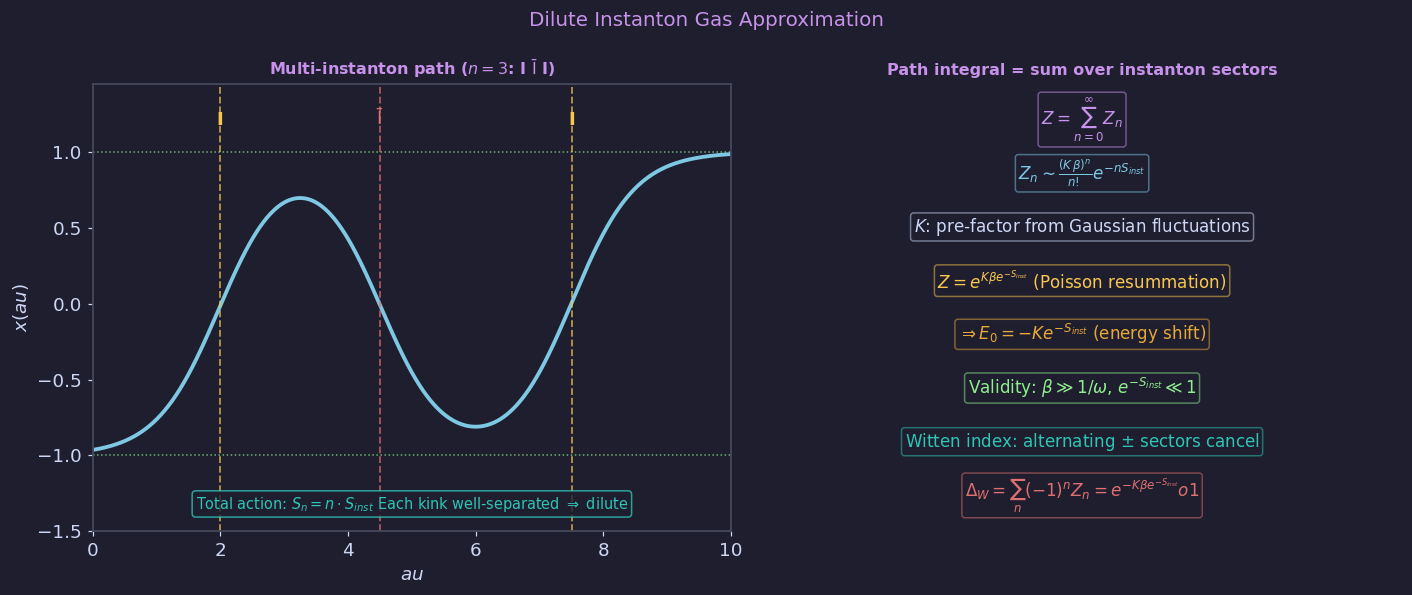

In [5]:
# ── Figure 4: Dilute gas approximation ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('Dilute Instanton Gas Approximation', color=PURP, fontsize=13)

tau_full = np.linspace(0, 10, 1000)  # imaginary time on S^1 (β=10)

def kink(tau, tau0, sign=+1):
    return sign * np.tanh(tau - tau0)

# Left: multi-instanton configuration (I I-bar I)
ax = axes[0]
ax.set_facecolor(BG)
ax.set_title(r'Multi-instanton path ($n=3$: I $\bar{\mathrm{I}}$ I)',
             color=PURP, fontsize=10.5)

# Build a piecewise kink path: +1 → -1 → +1 → -1
centers = [2.0, 4.5, 7.5]
signs   = [+1, -1, +1]
x_path  = -np.ones_like(tau_full)
for tau0, sgn in zip(centers, signs):
    x_path += sgn * (np.tanh(tau_full - tau0) + 1)

# normalise to stay within ±1
x_path = np.clip(x_path, -1.2, 1.2)

ax.plot(tau_full, x_path, color=BLUE, lw=2.5)
ax.axhline( 1, color=GREEN, lw=1, ls=':', alpha=0.7)
ax.axhline(-1, color=GREEN, lw=1, ls=':', alpha=0.7)
for i, (c, sgn, col_k) in enumerate(zip(centers, signs, [YELL, RED, YELL])):
    ax.axvline(c, color=col_k, lw=1.2, ls='--', alpha=0.7)
    label = 'I' if sgn>0 else r'$\bar{\mathrm{I}}$'
    ax.text(c, 1.18, label, ha='center', fontsize=12, color=col_k, fontweight='bold')

ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$x(\tau)$')
ax.set_xlim(0, 10); ax.set_ylim(-1.5, 1.45)
ax.text(5, -1.35,
        r'Total action: $S_n = n \cdot S_{inst}$' + ' ' +
        r'Each kink well-separated $\Rightarrow$ dilute',
        ha='center', fontsize=9.5, color=TEAL,
        bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=TEAL, alpha=0.8))

# Right: partition function sum over instanton sectors
ax = axes[1]
ax.set_facecolor(BG)
ax.set_title('Path integral = sum over instanton sectors', color=PURP, fontsize=10.5)
ax.axis('off')

lines = [
    (0.5, 0.92, r'$Z = \sum_{n=0}^{\infty} Z_n$', PURP),
    (0.5, 0.80,
     r'$Z_n \sim \frac{(K\,\beta)^n}{n!} e^{-n S_{inst}}$',
     BLUE),
    (0.5, 0.68, r'$K$: pre-factor from Gaussian fluctuations', FG),
    (0.5, 0.56,
     r'$Z = e^{K\beta e^{-S_{inst}}}$ (Poisson resummation)',
     YELL),
    (0.5, 0.44,
     r'$\Rightarrow E_0 = -K e^{-S_{inst}}$ (energy shift)',
     ORAN),
    (0.5, 0.32,
     r'Validity: $\beta \gg 1/\omega$, $e^{-S_{inst}} \ll 1$',
     GREEN),
    (0.5, 0.20, r'Witten index: alternating $\pm$ sectors cancel', TEAL),
    (0.5, 0.08, r'$\Delta_W = \sum_n (-1)^n Z_n = e^{-K\beta e^{-S_{inst}}}$'
                r'$\to 1$', RED),
]
for x_, y_, txt, col in lines:
    ax.text(x_, y_, txt, ha='center', va='center', fontsize=11, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.18', fc=BG, ec=col, alpha=0.5))

plt.tight_layout()
save('fig04_dilute_gas.png', fig)


  saved -> figures/ch02/fig05_zero_modes.png


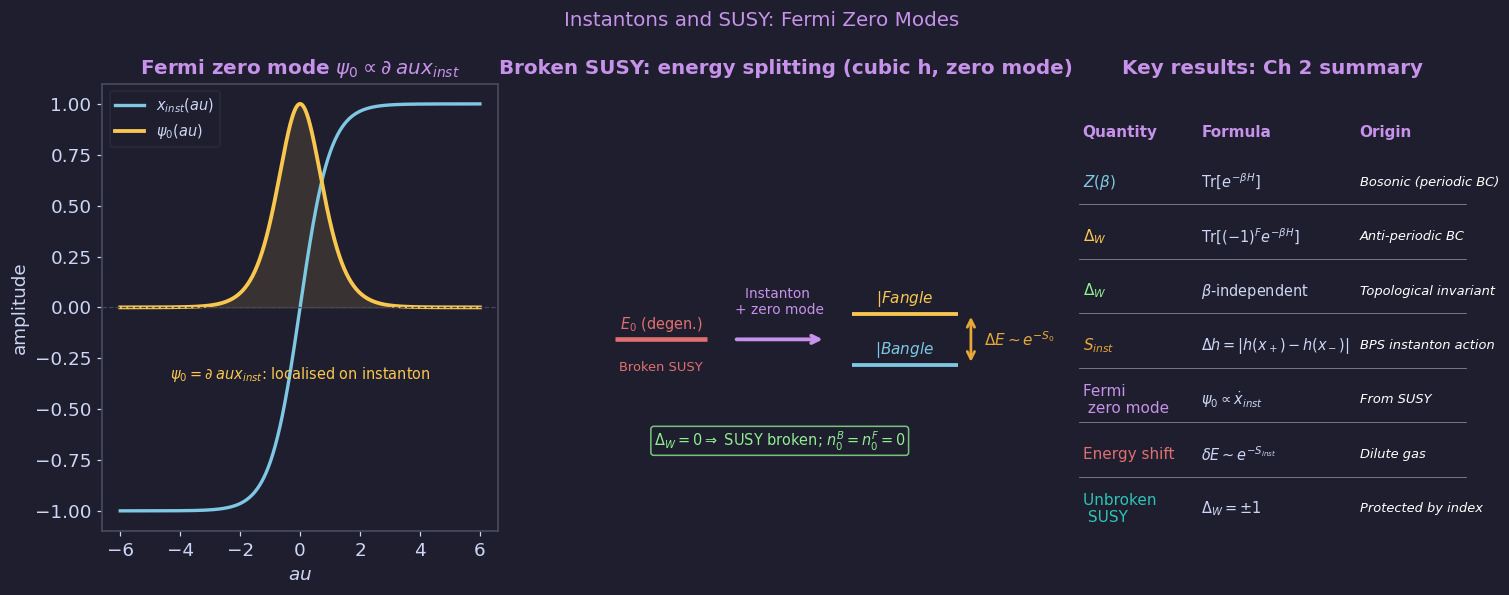

In [6]:
# ── Figure 5: Fermi zero modes and ground state energy ─────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
fig.suptitle('Instantons and SUSY: Fermi Zero Modes', color=PURP, fontsize=13)

tau = np.linspace(-6, 6, 600)

# Instanton profile
x0 = np.tanh(tau)
# Fermi zero mode: ψ_0 ∝ dx_inst/dτ = sech^2(τ)
psi_0 = 1.0 / np.cosh(tau)**2
psi_0 /= psi_0.max()

# Left: zero mode profile on top of instanton
ax = axes[0]
ax.set_facecolor(BG)
ax.set_title(r'Fermi zero mode $\psi_0 \propto \partial_\tau x_{inst}$', color=PURP)
ax.plot(tau, x0,    color=BLUE, lw=2.2, label=r'$x_{inst}(\tau)$')
ax.plot(tau, psi_0, color=YELL, lw=2.5, label=r'$\psi_0(\tau)$')
ax.fill_between(tau, 0, psi_0, color=YELL, alpha=0.12)
ax.axhline(0, color=EDGE, lw=0.8, ls='--')
ax.set_xlabel(r'$\tau$'); ax.set_ylabel('amplitude')
ax.legend(fontsize=9.5)
ax.text(0, -0.35, r'$\psi_0 = \partial_\tau x_{inst}$: localised on instanton',
        ha='center', fontsize=9.5, color=YELL)

# Middle: SUSY and zero mode — bosonic vs fermionic sectors
ax = axes[1]
ax.set_facecolor(BG)
ax.set_title('Broken SUSY (cubic h): instantons lift the vacuum', color=PURP)
ax.set_xlim(0, 3.4); ax.set_ylim(-0.1, 2.0); ax.axis('off')
# Perturbatively: one E=0 state in each well (|B> at one vacuum, |F> at the other)
ax.hlines(0.4, 0.2, 0.9, colors=BLUE, lw=3); ax.text(0.55, 0.47, r'$|B\rangle$', ha='center', color=BLUE)
ax.hlines(0.4, 0.2, 0.9, colors=YELL, lw=1.2, linestyles='--')
ax.text(0.55, 0.22, r'$E=0$ to all orders', ha='center', fontsize=9, color=FG)
ax.text(0.55, 0.10, r'(one state per well, $|B\rangle$ and $|F\rangle$)', ha='center', fontsize=8, color=FG)
ax.annotate('', xy=(1.9, 0.9), xytext=(1.0, 0.45), arrowprops=dict(arrowstyle='->', color=PURP, lw=2.5))
ax.text(1.35, 0.95, 'instanton\n$\\langle F|Q|B\\rangle\\sim e^{-S_0}$', ha='center', fontsize=9, color=PURP)
ax.hlines(1.0, 2.0, 2.8, colors=BLUE, lw=2.5); ax.hlines(1.0, 2.0, 2.8, colors=YELL, lw=1.2, linestyles='--')
ax.text(2.4, 1.08, r'$|B\rangle,|F\rangle$ paired', ha='center', fontsize=9.5, color=FG)
ax.text(2.4, 0.82, r'$E_0\sim e^{-2S_0}>0$', ha='center', fontsize=10, color=ORAN)
ax.text(1.6, 1.6, r'$\Delta_W=0$: no $E=0$ state; SUSY broken non-perturbatively', ha='center', fontsize=9.5,
        color=GREEN, bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=GREEN, alpha=0.8))

# Right: summary table
ax = axes[2]
ax.set_facecolor(BG)
ax.set_title('Key results: Ch 2 summary', color=PURP)
ax.axis('off')

rows = [
    (r'$Z(\beta)$',             r'$\mathrm{Tr}[e^{-\beta H}]$',   r'$x$ periodic, $\psi$ anti-periodic',  BLUE),
    (r'$\Delta_W$',             r'$\mathrm{Tr}[(-1)^F e^{-\beta H}]$', r'$\psi$ periodic', YELL),
    (r'$\Delta_W$',             r'$\beta$-independent',            r'Topological invariant',  GREEN),
    (r'$S_{inst}$',             r'$\Delta h = |h(x_+)-h(x_-)|$',  r'BPS instanton action',   ORAN),
    ('Fermi \n zero mode',        r'$\psi_0 \propto \dot{x}_{inst}$', r'From SUSY',            PURP),
    ('Energy shift',           r'$E_0 \sim e^{-2S_{inst}}$',  r'Dilute gas',             RED),
    ('Unbroken \n SUSY',          r'$\Delta_W = \pm 1$',             r'Protected by index',     TEAL),
]
ys = np.linspace(0.78, 0.05, len(rows))
for (qty, val, desc, col), y in zip(rows, ys):
    ax.text(0.02, y, qty,  fontsize=10, color=col,  va='center', transform=ax.transAxes)
    ax.text(0.32, y, val,  fontsize=9.5, color=FG,  va='center', transform=ax.transAxes)
    ax.text(0.72, y, desc, fontsize=8.5, color="white", va='center', transform=ax.transAxes,
            style='italic')
    ax.plot([0.01, 0.99], [y - 0.05, y - 0.05],
        color="white", lw=0.5, alpha=0.5, transform=ax.transAxes)
# Header
ax.text(0.02, 0.88, 'Quantity', fontsize=10, color=PURP, fontweight='bold', transform=ax.transAxes)
ax.text(0.32, 0.88, 'Formula',  fontsize=10, color=PURP, fontweight='bold', transform=ax.transAxes)
ax.text(0.72, 0.88, 'Origin',   fontsize=10, color=PURP, fontweight='bold', transform=ax.transAxes)

plt.tight_layout()
save('fig05_zero_modes.png', fig)


In [7]:
import shutil
shutil.make_archive('susyqm_ch02_figures', 'zip', 'figures/ch02')
try:
    from google.colab import files
    files.download('susyqm_ch02_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to figures/ch02/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
